# Part 1: Filters and Edges

This notebook uses `filters_helpers.py` (finite-difference and DoG filters and display helpers), `convolution.py`, and the starter pack (`utils.py` for loading and showing images, and the images in `starter_pack/images`)

#### Setup cell. It imports the libraries and our own modules, then defines two helpers:
- `load(path, gray=False, max_side=1000)` loads an image with the starter's `load_image` and shrinks it with `cv2.resize` if its longer side exceeds 1000 px, keeping the aspect ratio
- `row(imgs, titles, name)` shows images side by side with the starter's `show` and saves the figure to `figs/` for the report

In [2]:
import os, time, sys
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
import cv2
from scipy.signal import convolve2d #for comparison pt 1.1
STARTER = Path("starter_pack")
sys.path.insert(0, str(STARTER / "code"))
from utils import load_image, show

IMG_ROOT = STARTER / "images"

from convolution import conv2d_loop, conv2d_vec, conv2d_sep, gaussian_kernel, separate
from filters_helpers import (Dx, Dy, to_gray, finite_diff, gradient_magnitude,dog_filters, dog_diff, signed_to_display)

os.makedirs("figs", exist_ok=True)  


def load(path, gray=False, max_side=1000):
    im = load_image(path, gray=gray)
    s = max_side/max(im.shape[:2])    #shrink keeping aspect ratio
    if s < 1:   
        im = cv2.resize(im, None, fx=s, fy=s, interpolation=cv2.INTER_AREA)
    return im

#save helper -lel report
def row(imgs, titles, name=None, size=4):
    if name is None:
        return show(*imgs, titles=titles, size=size)
    real_show = plt.show
    def show_and_save(*a, **k):
        plt.savefig(f"figs/{name}.png", dpi=150, bbox_inches="tight")
        real_show(*a, **k)
    plt.show = show_and_save
    try:
        show(*imgs, titles=titles, size=size)
    finally:
        plt.show = real_show

## Overview of core convolution module `convolution.py`:

The module provides the core functions required for convolution and filtering throughout the assignment.

- `padding()`: Pads an image according to the selected padding mode.
- `conv2d_loop()`: Implements 2D convolution using explicit loops over image pixels and kernel elements.
- `conv2d_vec()`: Implements 2D convolution using NumPy array operations to avoid looping over individual pixels.
- `separate()`: Uses SVD to check whether a kernel is separable and, if so, returns its column and row factors.
- `conv2d_sep()`: Applies separable convolution using two 1D filters when possible, falling back to vectorized convolution otherwise.
- `gaussian_kernel()`: Constructs a normalized 2D Gaussian kernel from the outer product of a 1D Gaussian vector with itself, producing a separable filter for image smoothing.  

#### Note on SVD and Tolerance:

SVD decomposes the kernel into $U$, $\Sigma$, and $V^T$. The singular values in $\Sigma$ are used to determine whether the kernel is separable.

A kernel is considered separable if its second singular value is negligible compared with the first. The relative tolerance `tol` allows for small numerical errors when checking this condition. If `S[1] > tol * S[0]`, the kernel is not considered separable; otherwise, the first singular vectors are used to recover the column and row factors.
> We use $\sigma = n/6$ because approximately 99.7% of a Gaussian's area lies within $\pm 3\sigma$ of its center. Since the kernel extends roughly $n/2$ pixels from its center to each edge, setting $(3\sigma \approx n/2)$ gives $(\sigma \approx n/6)$. This keeps nearly all significant Gaussian values within the kernel.

## 1.1 Convolution from scratch

In [3]:
#checking all 3 randoms and scipy, seperable / non seperable
rng = np.random.default_rng(0)
for trial in range(50):
    img = rng.random((rng.integers(5, 25), rng.integers(5, 25)))
    kh, kw = rng.choice([1, 3, 5, 7, 9]), rng.choice([1, 3, 5, 7, 9])
    for k in (rng.random((kh, kw)), np.outer(rng.random(kh), rng.random(kw))):  # non-separable, separable
        ref = convolve2d(img, k, mode="same")   #scipy.signal function
        for f in (conv2d_loop, conv2d_vec, conv2d_sep):
            assert np.allclose(f(img, k), ref, atol=1e-10), (f.__name__, k.shape)

  size   loop (s)   vectorized (s)   separable (s)
  3x3       0.187           0.0004          0.0005
  5x5       0.462           0.0011          0.0006
  7x7       0.888           0.0020          0.0007
  9x9       1.478           0.0047          0.0015
 11x11      2.108           0.0051          0.0010
 13x13      2.918           0.0071          0.0012
 15x15      3.785           0.0089          0.0013
 17x17      4.818           0.0116          0.0014
 19x19      8.403           0.0161          0.0019
 21x21     10.031           0.0199          0.0029
 23x23     13.211           0.0337          0.0019
 25x25     17.589           0.0319          0.0033
 27x27     18.808           0.0506          0.0044
 29x29     23.704           0.0409          0.0023
 31x31     26.248           0.0684          0.0030


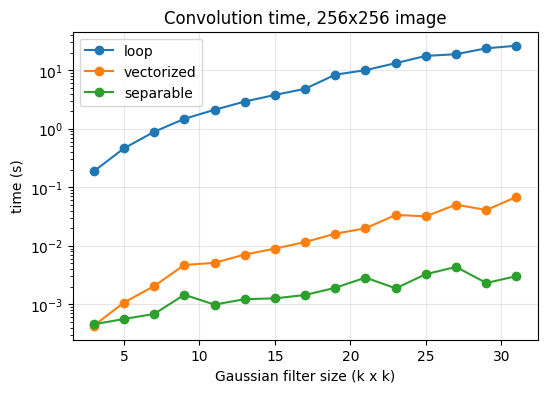

In [ ]:
img256 = np.random.default_rng(1).random((256, 256))
sizes = list(range(3, 32, 2))
LOOP_SIZES = sizes

def best_time(f, img, k, reps):
    ts = []
    for _ in range(reps):
        t = time.perf_counter(); 
        f(img, k); ts.append(time.perf_counter() - t)
    return min(ts)

T = {"loop": {}, "vectorized": {}, "separable": {}}
for n in sizes:
    k = gaussian_kernel(n, sigma=n / 6)
    assert separate(k) is not None
    if n in LOOP_SIZES: T["loop"][n] = best_time(conv2d_loop, img256, k, 1)
    T["vectorized"][n] = best_time(conv2d_vec, img256, k, 5)
    T["separable"][n] = best_time(conv2d_sep, img256, k, 5)

print(f"{'size':>6} {'loop (s)':>10} {'vectorized (s)':>16} {'separable (s)':>15}")
for n in sizes:
    l = f"{T['loop'][n]:.3f}" if n in T["loop"] else "-"
    print(f"{n:>3}x{n:<2} {l:>10} {T['vectorized'][n]:>16.4f} {T['separable'][n]:>15.4f}")

plt.figure(figsize=(6, 4))
for name, d in T.items():
    plt.semilogy(list(d), list(d.values()), "o-", label=name)
plt.xlabel("Gaussian filter size (k x k)"); plt.ylabel("time (s)"); plt.legend(); plt.grid(alpha=.3)
plt.title("Convolution time, 256x256 image")
plt.savefig("figs/timing.png", dpi=150, bbox_inches="tight"); plt.show()

### Time difference
- Loop: about H·W·k² Python-level multiply-adds; the interpreter overhead per operation dominates, so it is orders of magnitude slower and grows as k².  
- Vectorized: only k² iterations, each a whole-image NumPy operation running in compiled code. Still O(H·W·k²) arithmetic, but with small per-element cost.  
- Separable: two 1D passes, 2k whole-image operations, so O(H·W·k): linear in k instead of quadratic. The gap to the vectorized version widens as the filter grows.  
- The SVD rank test costs almost nothing (k is small).

## 1.2 Finite difference operator

An edge is a sharp change in intensity, and derivatives measure change. For each image the flow is as follows:

1. The image is loaded in grayscale, at most 1000 px on the longer side.
2. Its filtered with Dx = [1 0 -1] and Dy = Dx transposed, using our separable convolution with zero padding. This gives the two derivative maps.
3. Combined into the gradient magnitude, sqrt((dI/dx)^2 + (dI/dy)^2).
4. Magnitude is binarized with a threshold to get the edge image. We first sweep several thresholds and pick one per image.  
> T: gradient magnitude threshold (or edge detection threshold), determines the minimum gradient magnitude a pixel must have to be classified as an edge.

In [37]:
images = {"cameraman": load(IMG_ROOT / "part1_filters" / "cameraman.png", gray=True), "facade": load(IMG_ROOT / "part1_filters" / "facade.png", gray=True)}

result = {}
for name, g in images.items():
    gx, gy = finite_diff(g)
    result[name] = (gx, gy, gradient_magnitude(gx, gy))
gray, gray_f = images["cameraman"], images["facade"]

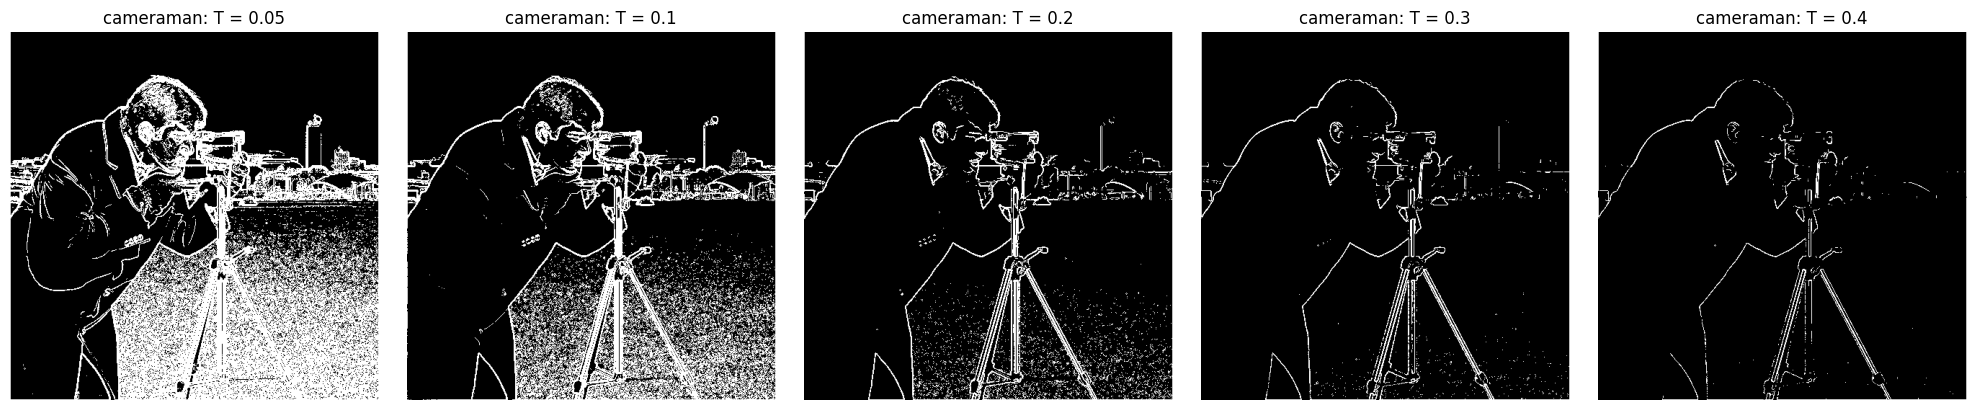

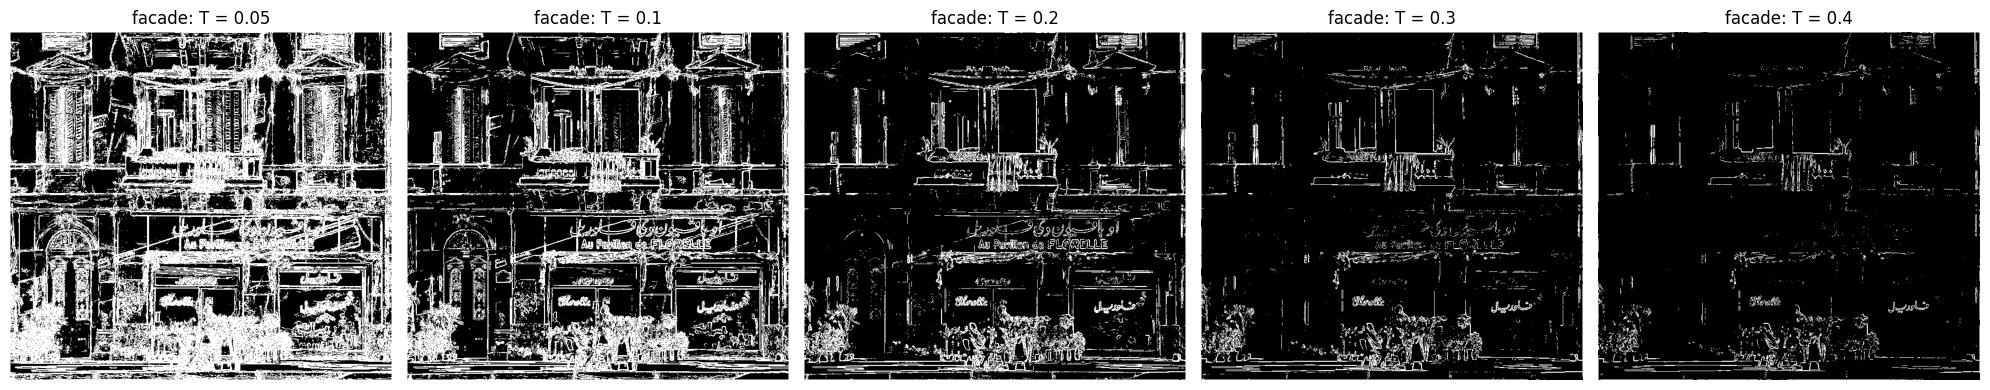

In [39]:
for name, (gx, gy, gm) in result.items():
    fig, ax = plt.subplots(1, 5, figsize=(20, 4))
    for a, t in zip(ax, [0.05, 0.1, 0.2, 0.3, 0.4]):
        a.imshow(gm > t, cmap="gray"); a.set_title(f"{name}: T = {t}"); a.axis("off")
    plt.tight_layout(); plt.show()

Low T (0.05): almost everything counts as an edge, so flat regions fill with noise speckle.  
High T (0.4): only the strongest edges survive, and real edges start to break up or vanish.
T = 0.2 is the lowest value that suppresses the noise in flat areas without losing the main contours. 

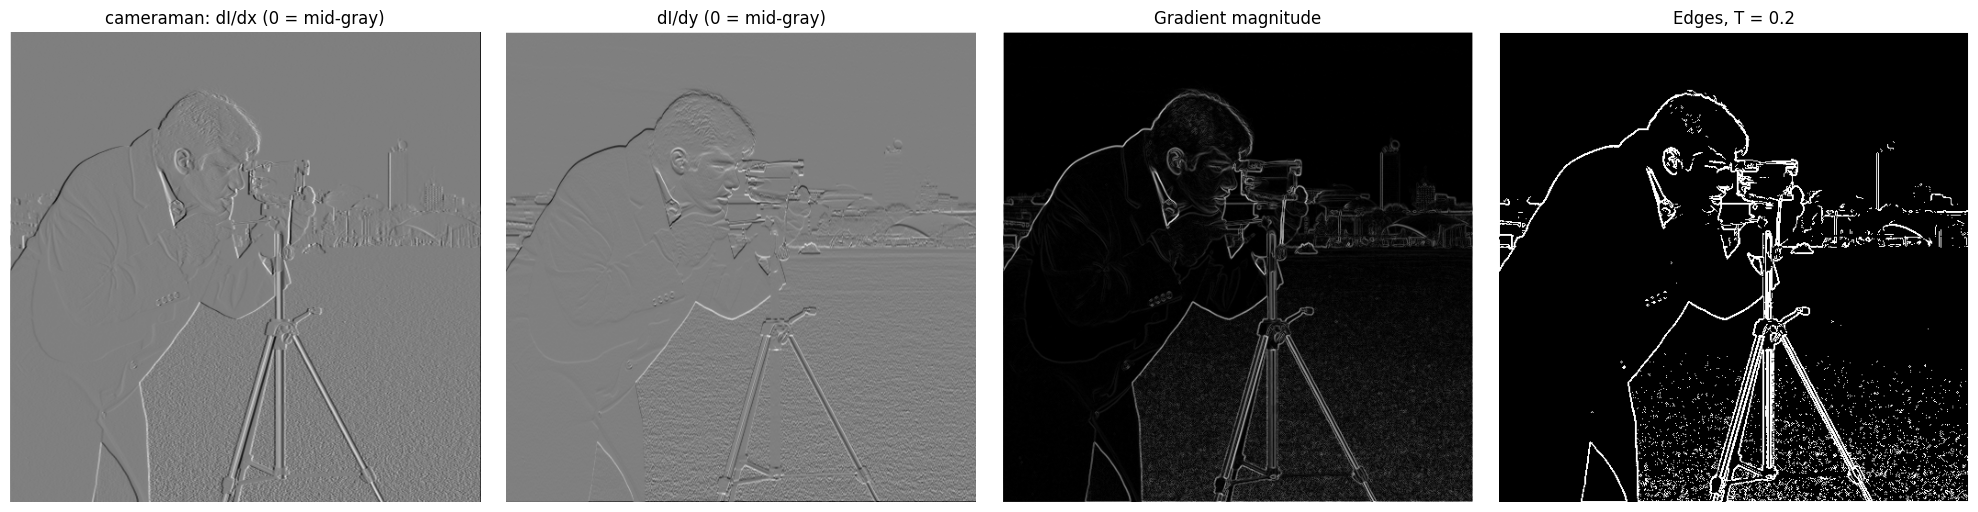

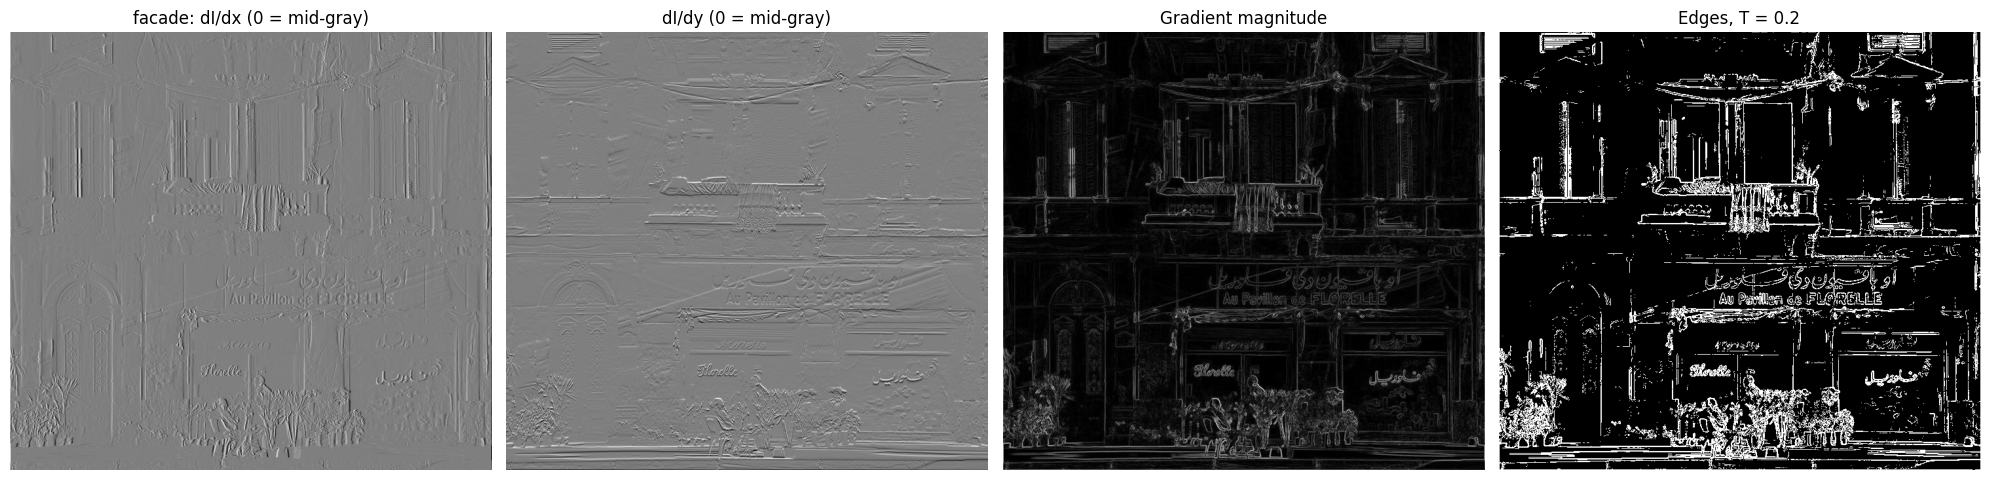

In [30]:
T12 = {"cameraman": 0.2, "facade": 0.2}
for name, (gx, gy, gm) in result.items():
    thr = T12[name]
    row([signed_to_display(gx), signed_to_display(gy), gm / gm.max(), (gm > thr).astype(float)],
        [f"{name}: dI/dx (0 = mid-gray)", "dI/dy (0 = mid-gray)", "Gradient magnitude", f"Edges, T = {thr}"],
        name=f"1_2_{name}", size=5)

edges = result["cameraman"][2] > T12["cameraman"]
edges_f = result["facade"][2] > T12["facade"]

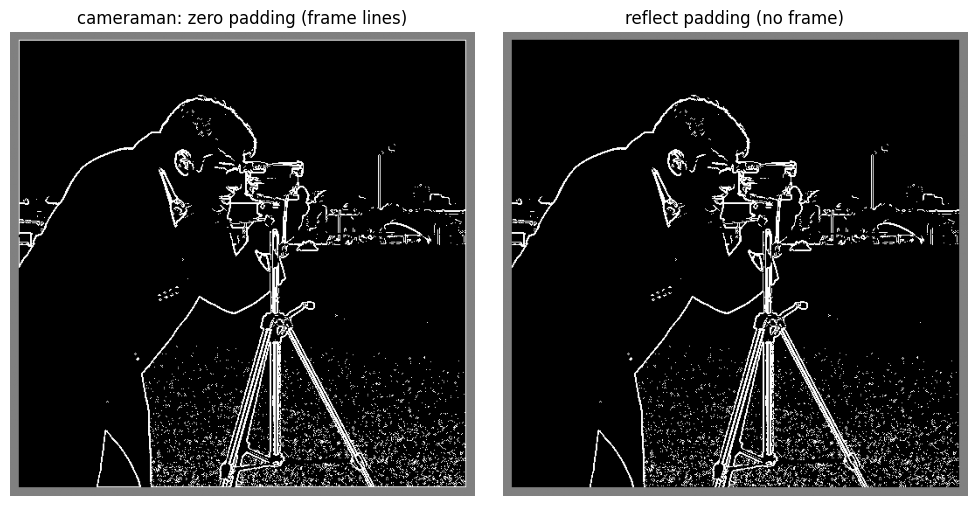

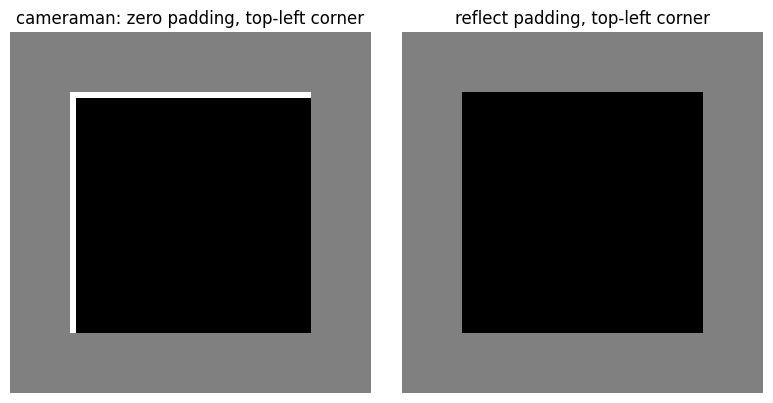

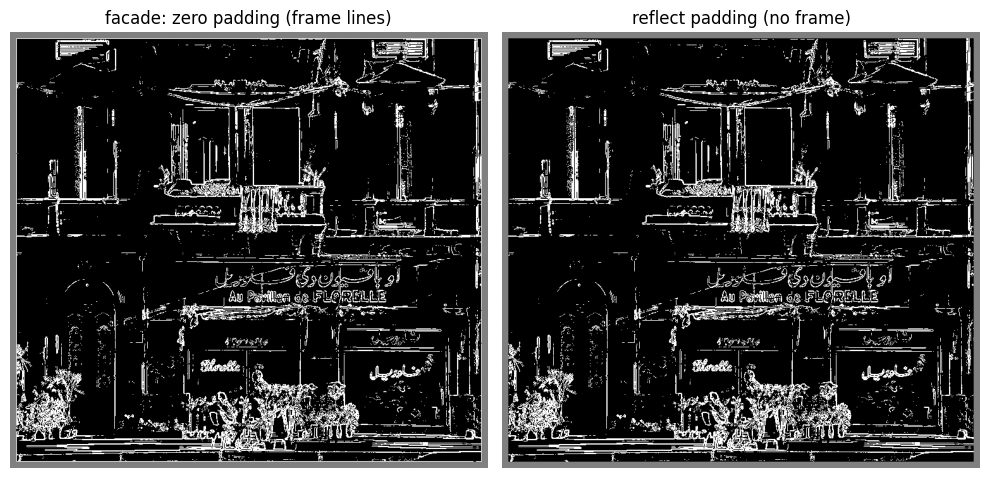

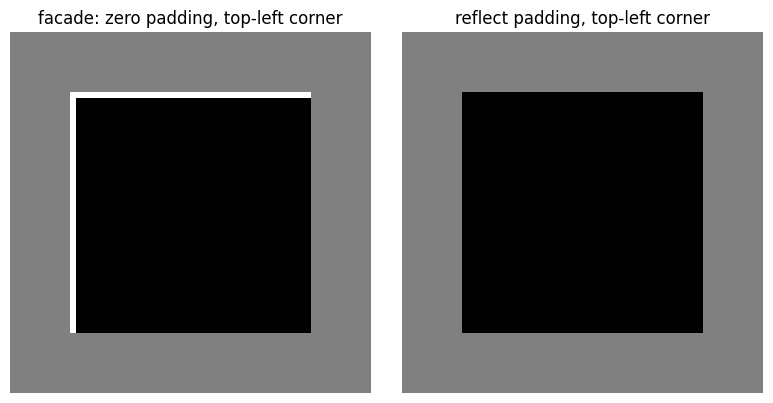

In [ ]:
def with_margin(e, m=10):
    return np.pad(e.astype(float), m, constant_values=0.5)  

for name, g in images.items():
    thr, gm = T12[name], result[name][2]
    gx_r, gy_r = finite_diff(g, pad_mode="reflect")
    gm_r = gradient_magnitude(gx_r, gy_r)
    
    row([with_margin(gm > thr), with_margin(gm_r > thr)],
        [f"{name}: zero padding (frame lines)", "reflect padding (no frame)"],
        name=f"1_2_frame_{name}", size=5)
    row([with_margin((gm > thr)[:40, :40]), with_margin((gm_r > thr)[:40, :40])],
        [f"{name}: zero padding, top-left corner", "reflect padding, top-left corner"],
        name=f"1_2_corner_{name}", size=4)

Convolution fills frames with zeros (black). So at the first and last row and column, the derivative filter compares a real pixel with a fake black one, so its is therefore detected as an edge.

## 1.3 Derivative of Gaussian (DoG)
**Parameters.** sigma = 2 (13x13 kernel). Threshold T = 0.08 for the cameraman and T = 0.06 for the facade, chosen from the sweeps above. In 1.2 we used T = 0.2 for both.

$$
\text{SIZE} = 2\lceil 3\sigma \rceil + 1
$$

**How the maps differ from 1.2.**
- The DoG maps are smoother. The speckle that finite differences produce on textured areas (the grass in the cameraman) is gone.
- The edges are continuous and thicker. Finite differences give thin, broken lines, while DoG gives wide, connected contours.
- Fine detail is lost. Thin lines and small text that 1.2 picks up are weakened or missing, and only the main structure survives (the cameraman's outline and tripod, the facade's windows, balcony and arch).
- The gradient magnitudes are smaller, so the threshold had to drop from 0.2 to 0.08 and 0.06.

**Reason**
- Differentiating amplifies noise: a derivative compares neighboring pixels, so any small random variation turns into a large response. In 1.2 the derivative sees the raw pixels, so noise and fine texture produce edges.
- The DoG blurs and differentiates in one filter, since (I * G) * Dx = I * (G * Dx). The Gaussian averages neighboring pixels first, so noise and texture are smoothed out before the derivative, and only changes that persist over a few pixels remain.
- The same averaging spreads each edge over about sigma pixels, which makes the contours thicker. It also lowers the peak gradient, which is why the threshold has to be lower.
- A larger sigma would remove more detail and give thicker edges, and a smaller sigma would behave more like 1.2.

**Check.** One DoG convolution matches blurring first and then differentiating, up to a difference of about 0.002 that comes from truncating the Gaussian to 13x13.

In [ ]:
SIGMA = 2
SIZE = int(2 * np.ceil(3 * SIGMA) + 1)
dogx, dogy = dog_filters(SIZE, SIGMA)
print("DoG kernels separable:", separate(dogx) is not None, separate(dogy) is not None)

G = gaussian_kernel(SIZE, SIGMA)
g = images["cameraman"]
dx_g, _ = dog_diff(g, dogx, dogy)
two_step = conv2d_sep(conv2d_sep(g, G), Dx)
print("max diff vs blur-then-Dx (interior):", np.abs(two_step - dx_g)[SIZE:-SIZE, SIZE:-SIZE].max())

DoG kernels separable: True True
max diff vs blur-then-Dx (interior): 0.002089098152031732


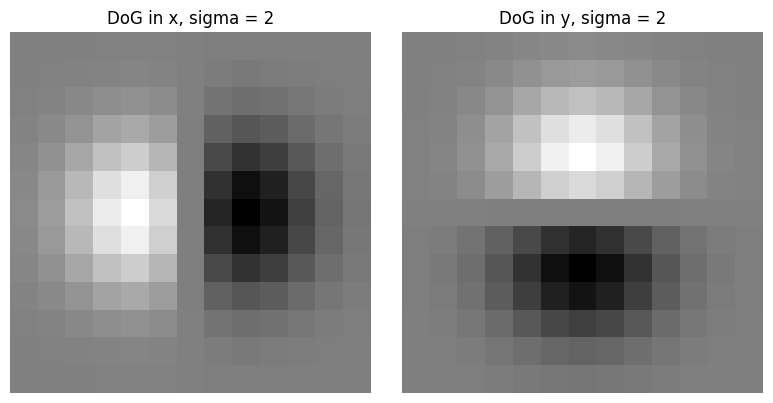

In [34]:
row([signed_to_display(dogx), signed_to_display(dogy)],
    [f"DoG in x, sigma = {SIGMA}", f"DoG in y, sigma = {SIGMA}"], name="1_3_filters", size=4)

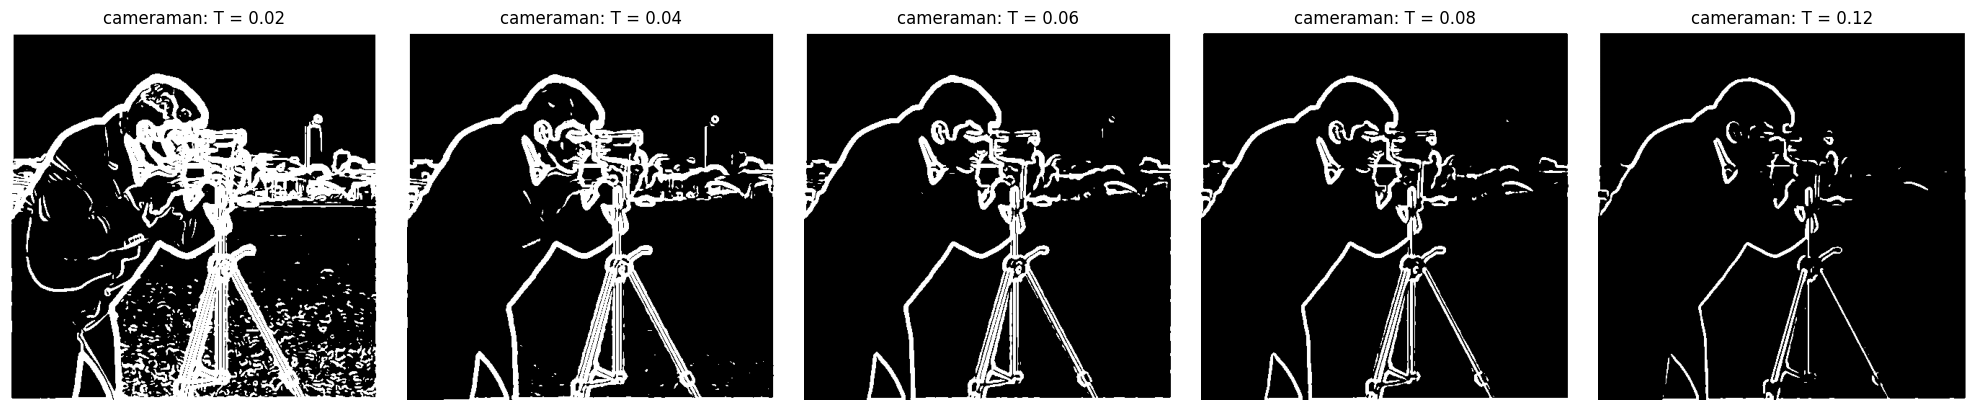

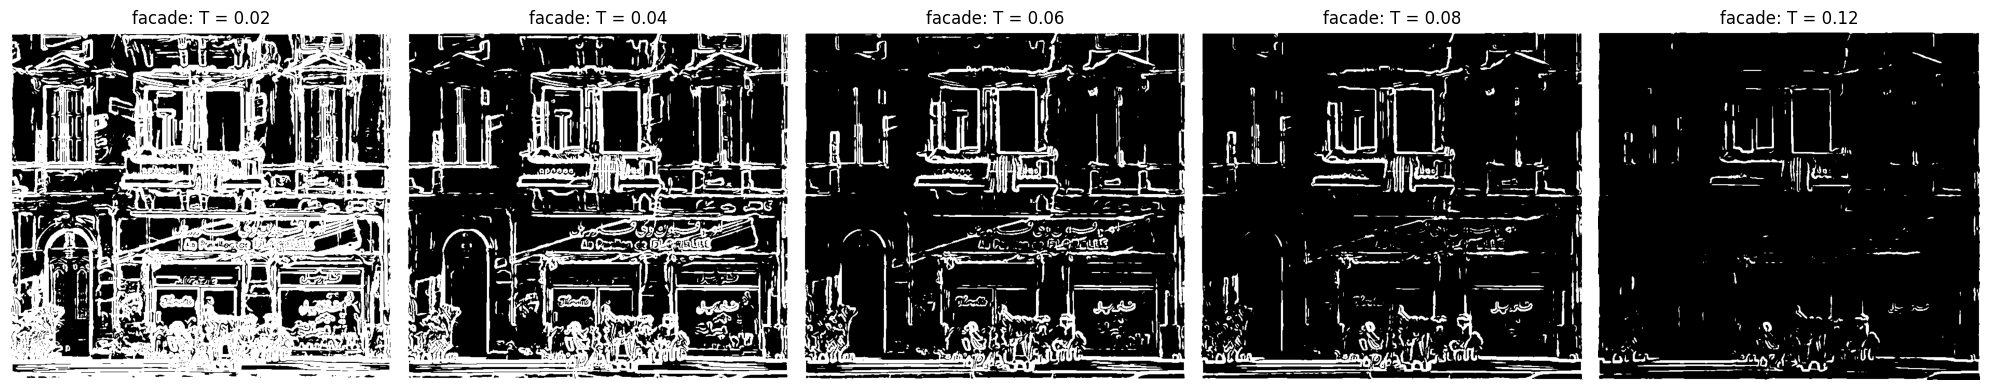

In [35]:
res13 = {}
for name, g in images.items():
    dx, dy = dog_diff(g, dogx, dogy)
    res13[name] = (dx, dy, gradient_magnitude(dx, dy))

for name, (dx, dy, gm) in res13.items():
    fig, ax = plt.subplots(1, 5, figsize=(20, 4))
    for a, t in zip(ax, [0.02, 0.04, 0.06, 0.08, 0.12]):
        a.imshow(gm > t, cmap="gray"); a.set_title(f"{name}: T = {t}"); a.axis("off")
    plt.tight_layout(); plt.show()

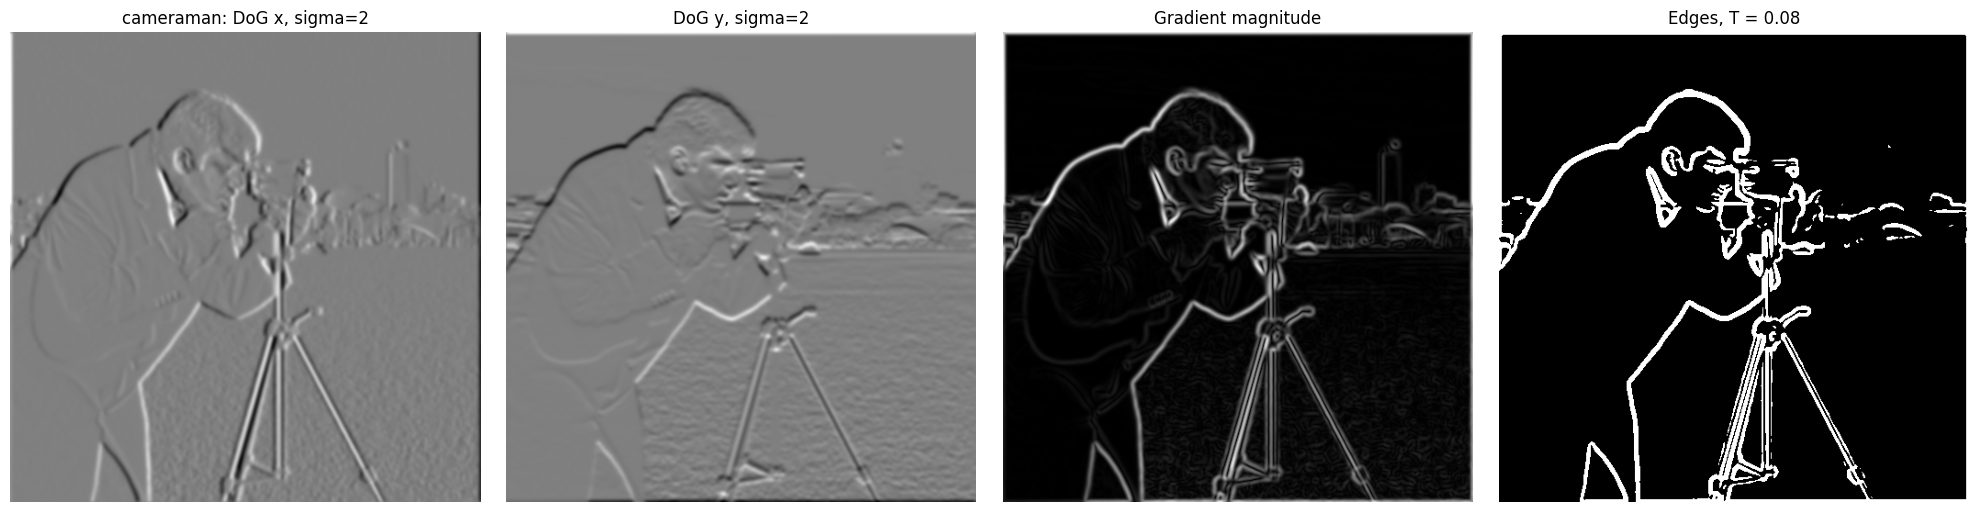

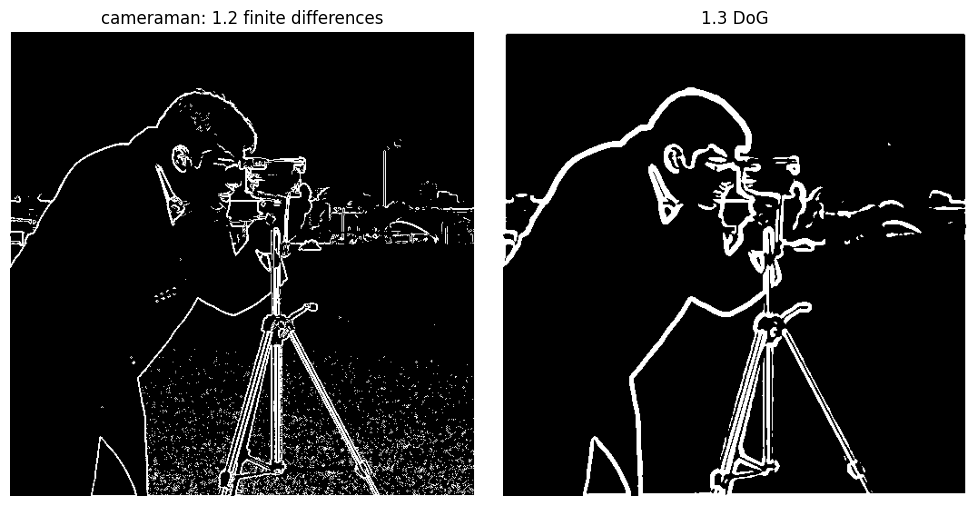

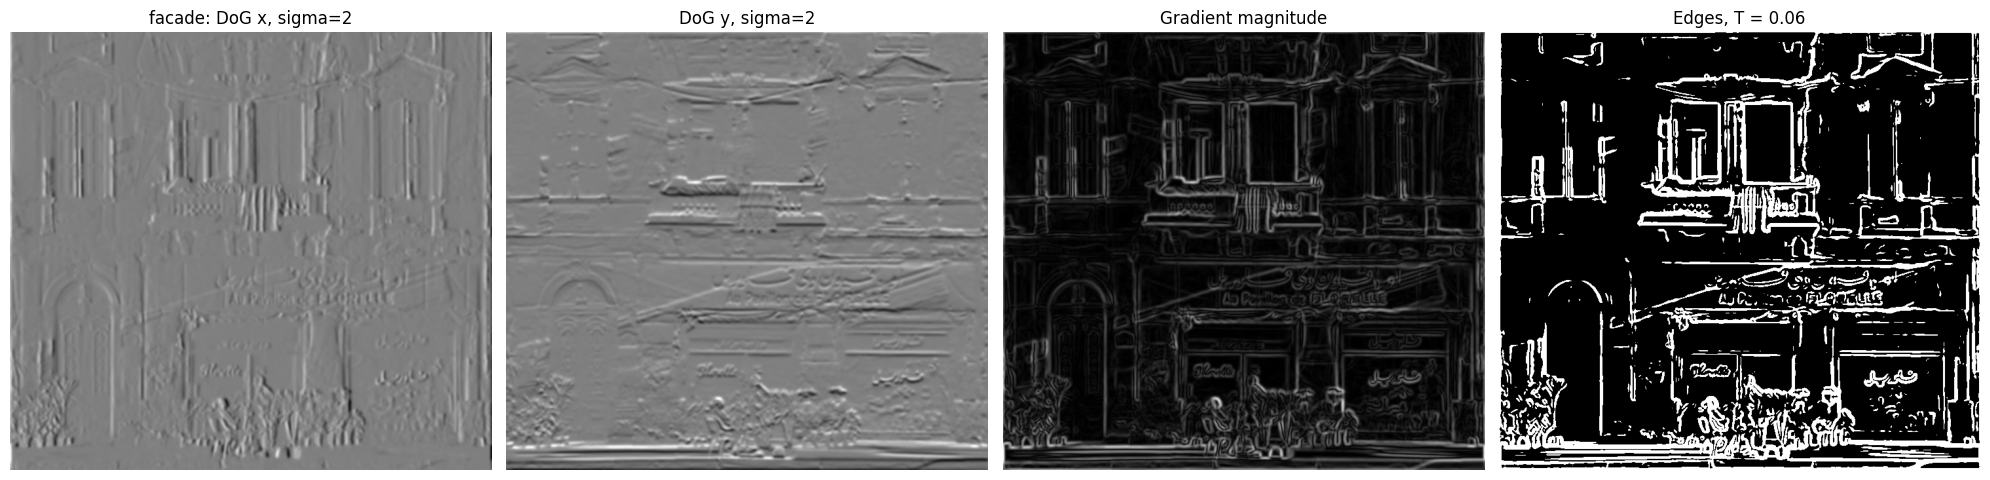

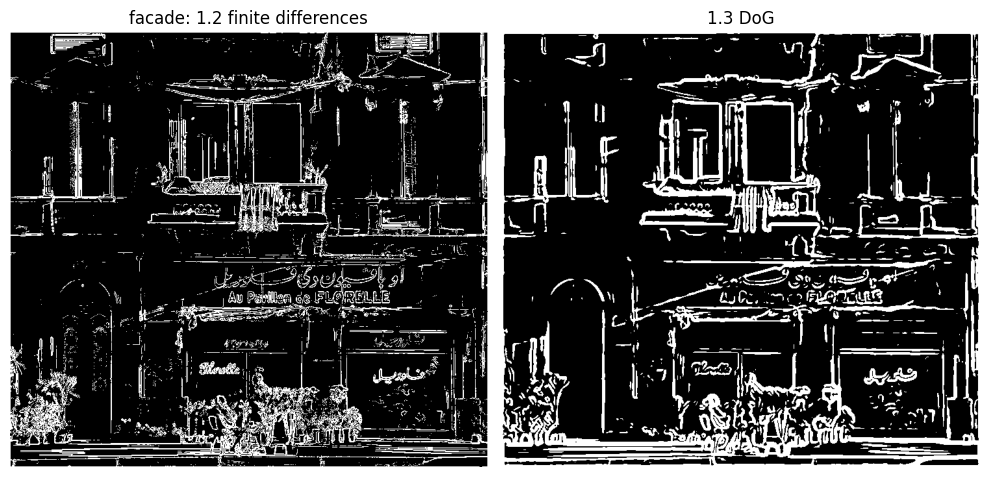

In [ ]:
T13 = {"cameraman": 0.08, "facade": 0.06}

for name, (dx, dy, gm) in res13.items():
    thr = T13[name]
    e13 = gm > thr
    row([signed_to_display(dx), signed_to_display(dy), gm / gm.max(), e13.astype(float)],
        [f"{name}: DoG x, sigma={SIGMA}", f"DoG y, sigma={SIGMA}", "Gradient magnitude", f"Edges, T = {thr}"],
        name=f"1_3_{name}", size=5)
    e12 = result[name][2] > T12[name]
    row([e12.astype(float), e13.astype(float)], [f"{name}: 1.2 finite differences", "1.3 DoG"],
        name=f"1_3_compare_{name}", size=5)